# Практикалық жұмыс 9 -

**Шешім ағашы (Decision Tree)** — жіктеу және регрессия есептерінде қолданылатын бақылау арқылы оқыту алгоритмі. Оның түбір түйіннен, тармақтардан, ішкі түйіндерден және жапырақ түйіндерден тұратын иерархиялық ағаш құрылымы бар.

Шешім ағашы шешімді кезең-кезеңімен қабылдауға көмектесетін блок-схема сияқты жұмыс істейді:

- **Ішкі түйіндер** — белгілерге қойылатын шарттарды білдіреді.
- **Тармақтар** — шарттардың ықтимал нәтижелерін немесе белгі мәндерін көрсетеді.
- **Жапырақ түйіндер** — соңғы шешімді немесе модель болжамын көрсетеді.

Шешім ағаштары түсіндіруге ыңғайлы, икемді және деректерді алдын ала өңдеуді көп қажет етпейтіндіктен кеңінен қолданылады.

## Шешім ағашы қалай жұмыс істейді

DT деректер жиынын белгілердің (feature) мәндеріне қарай бөледі, нәтижесінде мүмкіндігінше «таза» (pure) ішкі жиындар пайда болады — яғни бір топтағы барлық элементтер бір класқа жатады. Әрбір **жапырақ түйін** (leaf node) соңғы нәтижені білдіреді: классификацияда бұл класс белгісі, ал регрессияда — үздіксіз сан мәні. Мұны мысал арқылы түсініп көрейік.

## Қысқаша түсінік

- **Ішкі түйіндер** — белгі бойынша шарт тексеріледі (мысалы, «Жас < 30 ме?»).
- **Тармақтар** — шарттың нәтижесіне байланысты деректердің бағытын көрсетеді.
- **Жапырақ түйіндер** — соңғы болжам беріледі: классификацияда көпшілік дауыспен анықталған класс, регрессияда сол топтағы мәндердің орташа мәні.
- Топтағы барлық нысандар бір класқа жатса, ол **таза** деп аталады және одан әрі бөлінбей, жапырақ түйінге айналады.

### Мысал

«Студент емтиханнан өте ме?» деген сұрақты шешетін ағаш:

1. Оқу сағаты ≥ 5 сағат па?
   - Иә → «Өтеді»
   - Жоқ → Келесі шартқа өту
2. Дәріске қатысуы ≥ 80% па?
   - Иә → «Өтуі мүмкін»
   - Жоқ → «Өтпейді»

Мұнда «Өтеді», «Өтуі мүмкін», «Өтпейді» — жапырақ түйіндер, ал сағат пен қатысу пайызы — бөлу үшін қолданылған белгілер. Ағаш әр бөлуде ең жақсы нәтиже беретін шартты таңдайды, әдетте топтарды неғұрлым таза ететін бөлінуді қалайды.

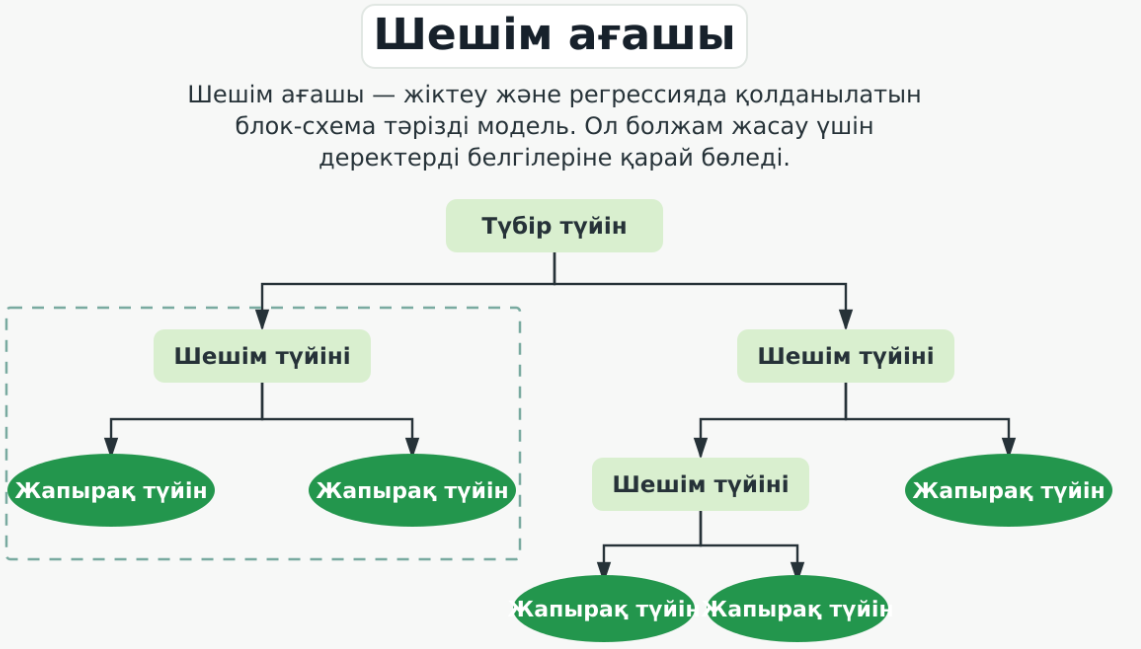

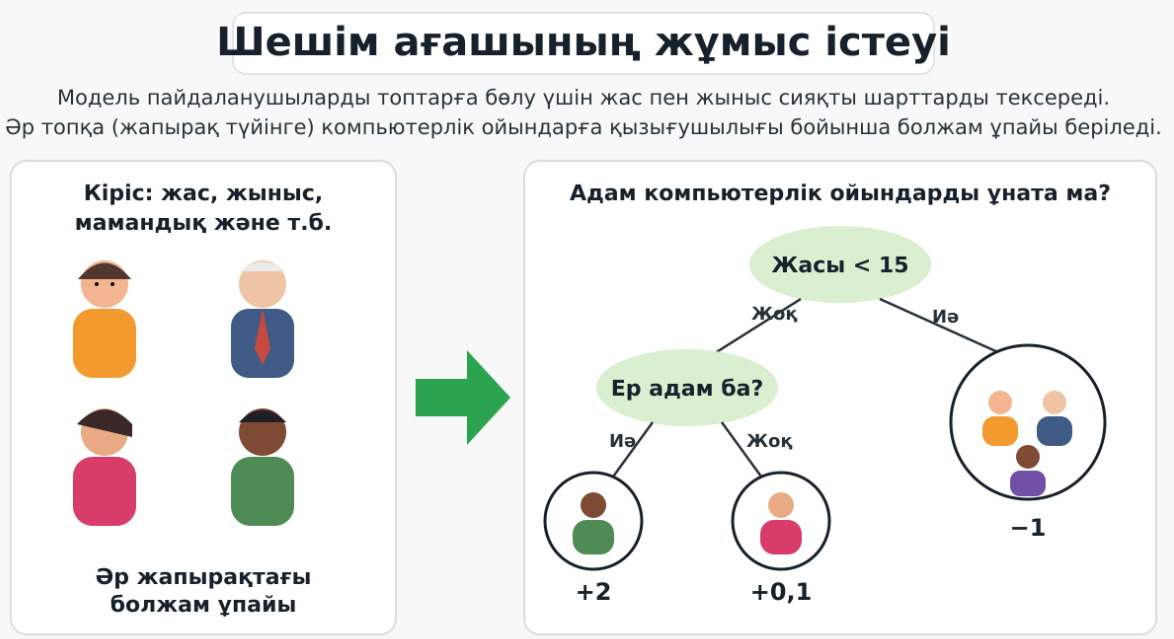

### Gini impurity — бір түйіндегі деректердің қаншалықты «аралас» екенін өлшейтін көрсеткіш. Ол 0-ге жақын болса, түйін таза; мәні үлкен болса, онда әр түрлі класс қатар жатыр. Decision Tree осы көрсеткішті пайдаланып, деректерді ең жақсы бөлетін шартты таңдайды.

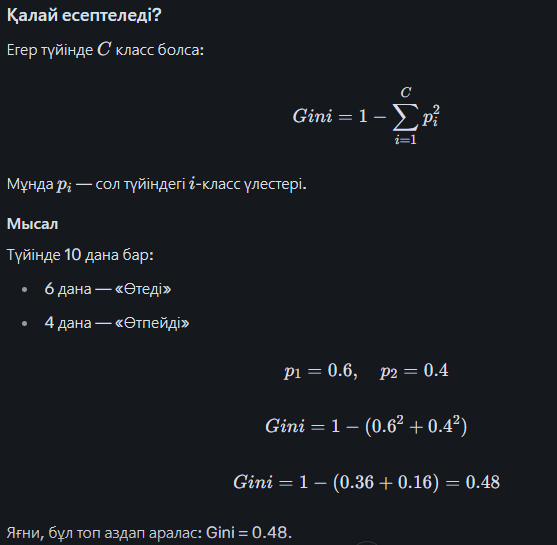

### Gini — «бұл топ қаншалықты аралас?» деген сұрақтың сандық жауабы, ал
### Decision Tree оны азайту арқылы жақсы бөлуді іздейді.

# МЫСАЛ - Decision Tree арқылы гүл түрін анықтау

**Мақсаты:** Iris датасетінде Decision Tree моделін құрып, гүлдің түрін (setosa, versicolor, virginica) болжау. Iris датасетінде 150 үлгі, 4 саналы белгі және 3 класс бар.

### 1-тапсырма. Деректерді жүктеу және зерттеу

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris(as_frame=True)
df = iris.frame

df.head()
df.info()
df.describe()
df["target"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


,count
target,
0,50
1,50
2,50


**Сұрақтар:**

- Датасетте қанша жол және қанша белгі бар?

- Әр классқа қанша үлгі келеді?

- Қай белгілердің орташа мәндері класс арасында ерекшеленеді?

### 2-тапсырма. Деректерді көрнекілеу

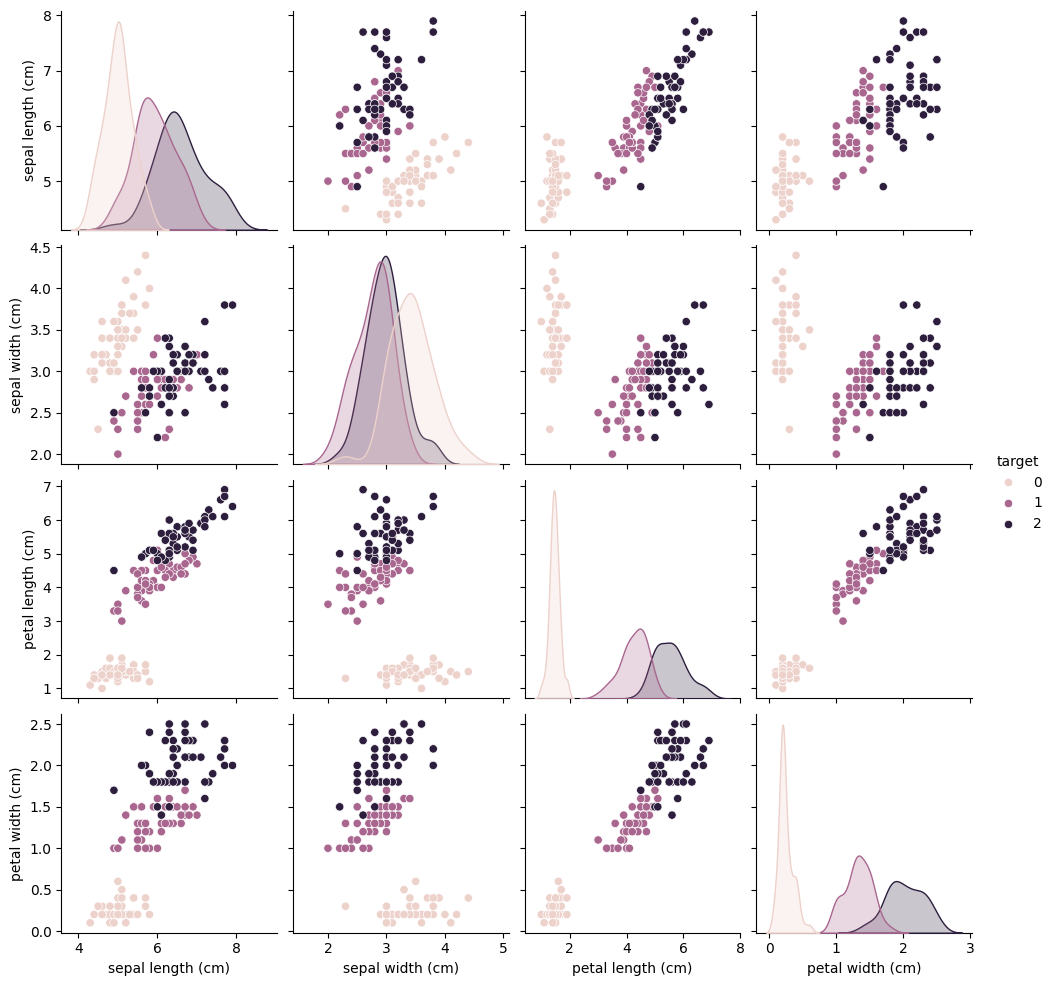

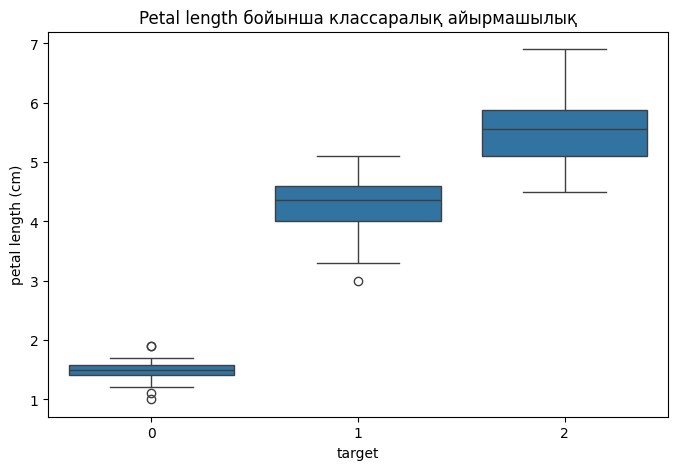

In [ ]:
sns.pairplot(df, hue="target")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="target", y="petal length (cm)")
plt.title("Petal length бойынша классаралық айырмашылық")
plt.show()

### 3-Тапсырма: Петал ұзындығы мен енінің гүл түрін ажыратуда маңызы бар-жоғын талдаңыз.

3-тапсырма. Модельді оқыту

In [ ]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

DecisionTreeClassifier — классификация үшін қолданылатын негізгі модель; criterion="gini" бөлінудің сапасын өлшейді.

### 4-тапсырма. Нәтижені бағалау

Accuracy: 0.9777777777777777
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      0.93      0.97        15
           2       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



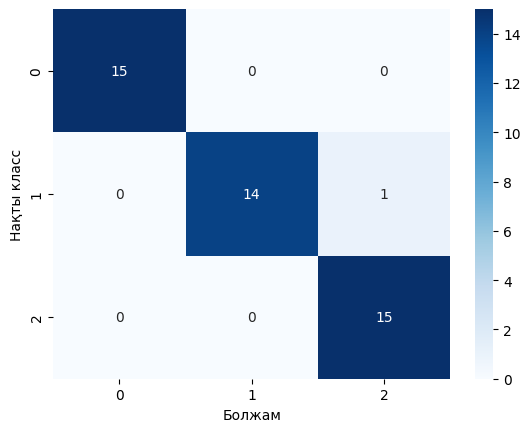

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Болжам")
plt.ylabel("Нақты класс")
plt.show()

### 5-тапсырма. Ағашты көрсету

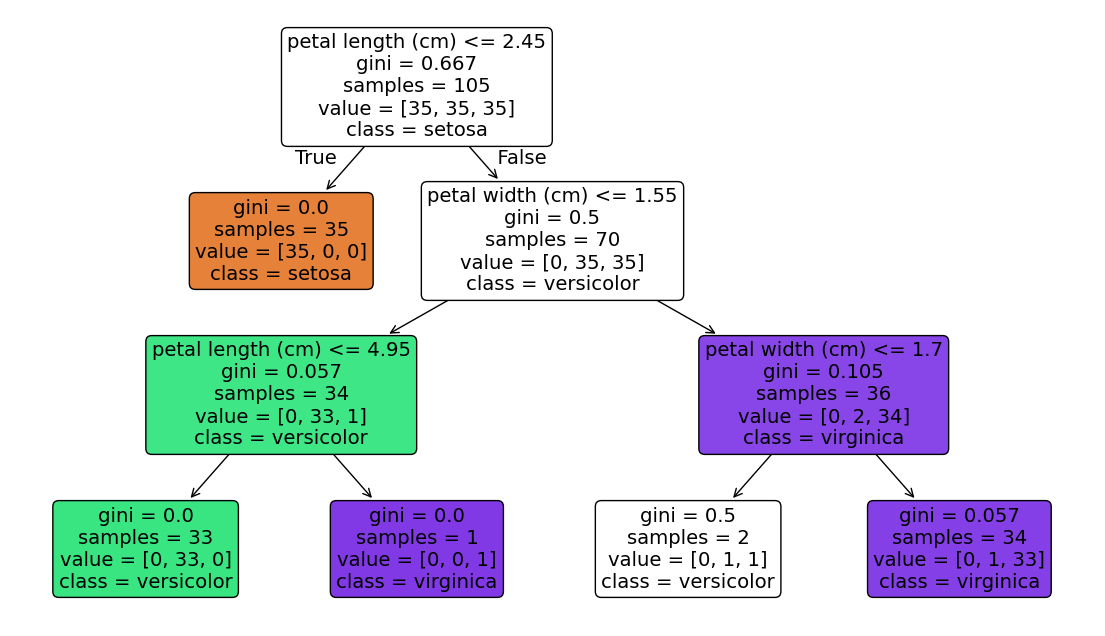

In [ ]:
plt.figure(figsize=(14, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)
plt.show()

Тапсырма: Ағаштың түбір түйінінде қандай шарт қолданылғанын жазыңыз. Бірінші бөлу қай белгі бойынша жасалды және неге?

### 6-тапсырма. max_depth параметрін зерттеу

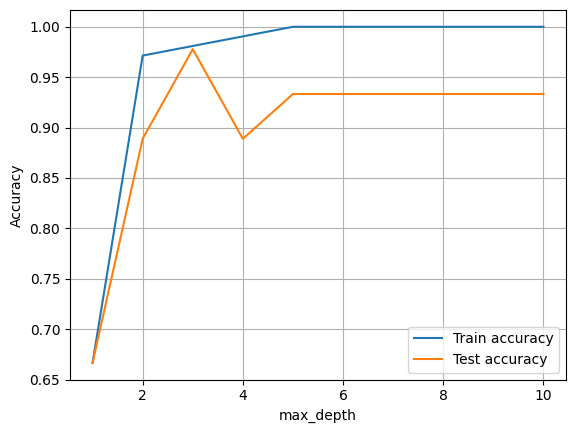

In [ ]:
train_scores = []
test_scores = []
depths = range(1, 11)

for d in depths:
    tree_model = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree_model.fit(X_train, y_train)

    train_scores.append(tree_model.score(X_train, y_train))
    test_scores.append(tree_model.score(X_test, y_test))

plt.plot(depths, train_scores, label="Train accuracy")
plt.plot(depths, test_scores, label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

### 7-тапсырма. Жаңа үлгіні болжау
### 8-тапсырма. Осы нәтижені басқа модельдермен салыстыру кестесін жасау